# Baselines Notebook
### Trying additional baselines for the project

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

In [2]:
# I need the images and the probs
# load C2 data (has everything)
c2_data = pd.read_csv("/zhome/d0/a/221493/thesis/results/C2_custom/effusion/c2_data.csv")

In [3]:
c2_data

,path,prob,true,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,Aorta_original_firstorder_Mean,Aorta_original_firstorder_Median,Aorta_original_firstorder_Minimum,Aorta_original_firstorder_Range,Aorta_original_firstorder_RobustMeanAbsoluteDeviation,Aorta_original_firstorder_RootMeanSquared,Aorta_original_firstorder_Skewness,Aorta_original_firstorder_TotalEnergy,Aorta_original_firstorder_Uniformity,Aorta_original_firstorder_Variance
0,CheXpert-v1.0-small/train/patient00005/study1/...,0.041813,0.0,-0.001189,-0.001186,0.002146,0.004988,-0.102878,0.176344,-0.001303,...,567.888093,646.393494,-65.630211,979.157249,150.293437,617.916926,-0.809970,1.172191e+08,0.039672,59324.441149
1,CheXpert-v1.0-small/train/patient00006/study1/...,0.215646,0.0,-0.001187,-0.003954,0.007097,0.003398,-0.039020,0.381182,-0.001332,...,34.056039,48.996605,-689.254150,1126.734589,96.362326,185.642746,-0.652183,3.511803e+07,0.041965,33303.415247
2,CheXpert-v1.0-small/train/patient00008/study1/...,0.989891,1.0,-0.001258,-0.002981,0.004603,0.001782,0.038358,0.399419,-0.001282,...,286.560282,357.584167,-409.044739,1017.673828,95.900233,347.399748,-1.382682,1.007733e+08,0.057587,38569.789807
3,CheXpert-v1.0-small/train/patient00008/study2/...,0.803473,1.0,-0.001191,-0.002815,0.002819,0.001348,0.057667,0.703849,-0.001344,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,CheXpert-v1.0-small/train/patient00010/study1/...,0.022443,0.0,-0.001185,-0.000544,0.002301,0.005169,-0.117937,-0.033050,-0.001290,...,213.656361,221.533264,-713.253662,1709.125610,216.630374,441.249354,-0.057772,1.177941e+08,0.020209,149051.951785
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45150,CheXpert-v1.0-small/train/patient47343/study4/...,0.254282,0.0,-0.001193,-0.000746,0.004451,0.002484,0.093905,0.294997,-0.001299,...,-78.911822,7.484866,-748.935486,996.037933,140.442993,239.189061,-0.828364,3.015041e+07,0.041562,50984.331080
45151,CheXpert-v1.0-small/train/patient47343/study5/...,0.190549,0.0,-0.001195,-0.000948,0.003515,0.003376,0.002050,0.100450,-0.001304,...,166.455575,249.356003,-590.689453,1055.035339,102.029540,280.504147,-1.452701,4.004943e+07,0.056241,50975.118192
45152,CheXpert-v1.0-small/train/patient47344/study4/...,0.999278,1.0,-0.001212,-0.003042,0.003746,-0.000372,0.070899,0.830360,-0.001302,...,437.703904,506.113647,-268.893646,969.057587,82.569345,474.512460,-1.599859,1.508586e+08,0.076489,33577.367070
45153,CheXpert-v1.0-small/train/patient47344/study3/...,0.997430,1.0,-0.001218,-0.002592,0.004545,0.002813,-0.001787,0.486378,-0.001291,...,369.637714,417.336212,-455.067108,1149.506439,98.581153,413.320162,-1.236381,1.482835e+08,0.050213,34201.516570


In [54]:
# Filter just what I want, the columns ['path', 'prob', 'true','margin','correct]
c2_data_filtered = c2_data[['path', 'prob','pred','true','margin','correct']]
c2_data_filtered

,path,prob,pred,true,margin,correct
0,CheXpert-v1.0-small/train/patient00005/study1/...,0.041813,0,0.0,0.521546,1
1,CheXpert-v1.0-small/train/patient00006/study1/...,0.215646,0,0.0,0.347713,1
2,CheXpert-v1.0-small/train/patient00008/study1/...,0.989891,1,1.0,0.426532,1
3,CheXpert-v1.0-small/train/patient00008/study2/...,0.803473,1,1.0,0.240114,1
4,CheXpert-v1.0-small/train/patient00010/study1/...,0.022443,0,0.0,0.540916,1
...,...,...,...,...,...,...
45150,CheXpert-v1.0-small/train/patient47343/study4/...,0.254282,0,0.0,0.309077,1
45151,CheXpert-v1.0-small/train/patient47343/study5/...,0.190549,0,0.0,0.372810,1
45152,CheXpert-v1.0-small/train/patient47344/study4/...,0.999278,1,1.0,0.435919,1
45153,CheXpert-v1.0-small/train/patient47344/study3/...,0.997430,1,1.0,0.434071,1


In [66]:
# Add entropy to c2_data_filtered BEFORE re-splitting
entropy = - (c2_data_filtered['prob'] * np.log(c2_data_filtered['prob']) + 
             (1 - c2_data_filtered['prob']) * np.log(1 - c2_data_filtered['prob']))
c2_data_filtered = c2_data_filtered.copy()
c2_data_filtered['entropy'] = entropy

In [61]:
# Split into 80/20 train/test
train_data = c2_data_filtered.sample(frac=0.8, random_state=42)
test_data = c2_data_filtered.drop(train_data.index)

In [67]:
# Define 5 cross validation folds
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Get the labels
y_train = train_data['correct'].values
y_test = test_data['correct'].values

### B1 - Just probabilities

In [ ]:
val_aucs = []
for train_index, val_index in kf.split(train_data):
    X_train_fold = train_data.iloc[train_index][['prob']]
    X_val_fold   = train_data.iloc[val_index][['prob']]
    y_train_fold = y_train[train_index]
    y_val_fold   = y_train[val_index]

    model = LogisticRegression()
    model.fit(X_train_fold, y_train_fold)
    y_val_prob = model.predict_proba(X_val_fold)[:, 1]
    val_auc = roc_auc_score(y_val_fold, y_val_prob)
    val_aucs.append(val_auc)
    print(f"Train Size: {len(X_train_fold)} Val Size: {len(X_val_fold)} | AUC: {val_auc:.4f}")

print("\nCross-Validation Results for B1 (Probs only):")
print(f"Average Validation AUC: {np.mean(val_aucs):.4f} ± {np.std(val_aucs):.4f}")

Train Size: 28899 Val Size: 7225 | AUC: 0.7437
Train Size: 28899 Val Size: 7225 | AUC: 0.7398
Train Size: 28899 Val Size: 7225 | AUC: 0.7444
Train Size: 28899 Val Size: 7225 | AUC: 0.7341
Train Size: 28900 Val Size: 7224 | AUC: 0.7242

Cross-Validation Results for B1 (Probs only):
Average Validation AUC: 0.7373 ± 0.0075


### B1.2 - Entropy 

In [79]:
# Add entropy to c2_data_filtered BEFORE re-splitting
entropy = - (c2_data_filtered['prob'] * np.log(c2_data_filtered['prob']) + 
             (1 - c2_data_filtered['prob']) * np.log(1 - c2_data_filtered['prob']))
c2_data_filtered = c2_data_filtered.copy()
c2_data_filtered['entropy'] = entropy


In [80]:
# %%
X_train = train_data[['entropy']]
y_train = train_data['correct'].values
X_val = test_data[['entropy']]
y_val = test_data['correct'].values

In [81]:
val_aucs = []
for train_index, val_index in kf.split(train_data):
    X_train_fold = train_data.iloc[train_index][['entropy']]
    X_val_fold   = train_data.iloc[val_index][['entropy']]
    y_train_fold = y_train[train_index]
    y_val_fold   = y_train[val_index]

    model = LogisticRegression()
    model.fit(X_train_fold, y_train_fold)
    y_val_prob = model.predict_proba(X_val_fold)[:, 1]
    val_auc = roc_auc_score(y_val_fold, y_val_prob)
    val_aucs.append(val_auc)
    print(f"Train Size: {len(X_train_fold)} Val Size: {len(X_val_fold)} | AUC: {val_auc:.4f}")

print("\nCross-Validation Results for B1.2 (Entropy only):")
print(f"Average Validation AUC: {np.mean(val_aucs):.4f} ± {np.std(val_aucs):.4f}")

Train Size: 28899 Val Size: 7225 | AUC: 0.8319
Train Size: 28899 Val Size: 7225 | AUC: 0.8364
Train Size: 28899 Val Size: 7225 | AUC: 0.8442
Train Size: 28899 Val Size: 7225 | AUC: 0.8388
Train Size: 28900 Val Size: 7224 | AUC: 0.8180

Cross-Validation Results for B1.2 (Entropy only):
Average Validation AUC: 0.8339 ± 0.0089


### B1.3 - Temperature Scaling
- T is fitted on a separate validation set, and then applied to the test set.
- The goal of T is to calibrate the probabilities, making them more reflective of true likelihoods.

In [88]:
# - Fit temperature T on each CV validation fold (not test set)
# - T scales the logits: p_calibrated = sigmoid(logit(p) / T)
# - T > 1 softens probabilities (less confident), T < 1 sharpens them

from scipy.special import logit, expit
from scipy.optimize import minimize_scalar
from sklearn.metrics import log_loss

def apply_temperature(probs, T):
    """Scale logits by temperature and return calibrated probs."""
    logits = logit(np.clip(probs, 1e-7, 1 - 1e-7))
    return expit(logits / T)

def fit_temperature(probs, labels):
    """Find T that minimises NLL on the given set."""
    def nll(T):
        calibrated = apply_temperature(probs, T)
        return log_loss(labels, calibrated)
    result = minimize_scalar(nll, bounds=(0.1, 10.0), method='bounded')
    return result.x

# %%
val_aucs = []
fitted_temps = []

for train_index, val_index in kf.split(train_data):
    train_fold = train_data.iloc[train_index]
    val_fold   = train_data.iloc[val_index]
    y_train_fold = y_train[train_index]
    y_val_fold   = y_train[val_index]

    # Fit T on the training fold, evaluate on val fold
    T = fit_temperature(train_fold['prob'].values, y_train_fold)
    fitted_temps.append(T)

    calibrated_val_probs = apply_temperature(val_fold['prob'].values, T)
    val_auc = roc_auc_score(y_val_fold, calibrated_val_probs)
    val_aucs.append(val_auc)
    print(f"Train Size: {len(train_fold)} Val Size: {len(val_fold)} | T={T:.4f} | AUC: {val_auc:.4f}")

print("\nCross-Validation Results for B1.3 (Temperature Scaling):")
print(f"Average Validation AUC: {np.mean(val_aucs):.4f} ± {np.std(val_aucs):.4f}")
print(f"Average fitted T: {np.mean(fitted_temps):.4f} ± {np.std(fitted_temps):.4f}")


Train Size: 28899 Val Size: 7225 | T=2.7493 | AUC: 0.7437
Train Size: 28899 Val Size: 7225 | T=2.7286 | AUC: 0.7398
Train Size: 28899 Val Size: 7225 | T=2.7326 | AUC: 0.7444
Train Size: 28899 Val Size: 7225 | T=2.7359 | AUC: 0.7341
Train Size: 28900 Val Size: 7224 | T=2.7332 | AUC: 0.7242

Cross-Validation Results for B1.3 (Temperature Scaling):
Average Validation AUC: 0.7373 ± 0.0075
Average fitted T: 2.7359 ± 0.0071


### B1.4 - Margin (ths - prob)

In [100]:
X_train = train_data[['margin']]
y_train = train_data['correct'].values
X_val = test_data[['margin']]
y_val = test_data['correct'].values
val_aucs = []
for train_index, val_index in kf.split(train_data):
    X_train_fold = train_data.iloc[train_index][['margin']]
    X_val_fold   = train_data.iloc[val_index][['margin']]
    y_train_fold = y_train[train_index]
    y_val_fold   = y_train[val_index]   
    model = LogisticRegression()
    model.fit(X_train_fold, y_train_fold)
    y_val_prob = model.predict_proba(X_val_fold)[:, 1]
    val_auc = roc_auc_score(y_val_fold, y_val_prob)
    val_aucs.append(val_auc)
    print(f"Train Size: {len(X_train_fold)} Val Size: {len(X_val_fold)} | AUC: {val_auc:.4f}")
    
print("\nCross-Validation Results for B1.4 (Margin):")
print(f"Average Validation AUC: {np.mean(val_aucs):.4f} ± {np.std(val_aucs):.4f}")



Train Size: 28899 Val Size: 7225 | AUC: 0.7197
Train Size: 28899 Val Size: 7225 | AUC: 0.7309
Train Size: 28899 Val Size: 7225 | AUC: 0.7329
Train Size: 28899 Val Size: 7225 | AUC: 0.7313
Train Size: 28900 Val Size: 7224 | AUC: 0.7178

Cross-Validation Results for B1.4 (Margin):
Average Validation AUC: 0.7265 ± 0.0064


### B1.5 - Distance to the counterfactual



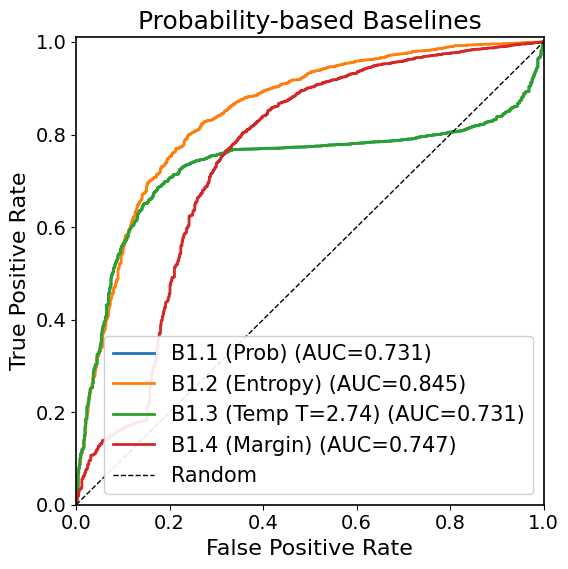


Test-Set AUC Summary:
  B1.1 (Prob): 0.7314
  B1.2 (Entropy): 0.8454
  B1.3 (Temp T=2.74): 0.7314
  B1.4 (Margin): 0.7468


In [106]:
# %% [markdown]
# ### ROC Curve Comparison (B1, B1.2, B1.3)
# Retrain each model on full train_data, evaluate on held-out test_data

# %%
from sklearn.metrics import roc_curve
from scipy.special import logit, expit

# B1 - Probs
m_b1 = LogisticRegression().fit(train_data[['prob']], y_train)
y_score_b1 = m_b1.predict_proba(test_data[['prob']])[:, 1]

# B1.2 - Entropy
m_b12 = LogisticRegression().fit(train_data[['entropy']], y_train)
y_score_b12 = m_b12.predict_proba(test_data[['entropy']])[:, 1]

# B1.3 - Temperature Scaling
T_final = fit_temperature(train_data['prob'].values, y_train)
y_score_b13 = apply_temperature(test_data['prob'].values, T_final)

# B1.4 - Margin
m_b14 = LogisticRegression().fit(train_data[['margin']], y_train)
y_score_b14 = m_b14.predict_proba(test_data[['margin']])[:, 1]

# %%
models = {
    'B1.1 (Prob)':          y_score_b1,
    'B1.2 (Entropy)':     y_score_b12,
    f'B1.3 (Temp T={T_final:.2f})': y_score_b13,
    'B1.4 (Margin)':      y_score_b14
}

fig, ax = plt.subplots(figsize=(6, 6))

for label, y_score in models.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)
    ax.plot(fpr, tpr, label=f'{label} (AUC={auc:.3f})', linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Probability-based Baselines')
ax.legend(loc='lower right', framealpha=0.9)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.01])
plt.tight_layout()
plt.savefig('roc_baselines.png', dpi=150, bbox_inches='tight')
plt.show()

# Print summary
print("\nTest-Set AUC Summary:")
for label, y_score in models.items():
    print(f"  {label}: {roc_auc_score(y_test, y_score):.4f}")